# 01 — Simulación fundamentada y verificación de los datos
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AlejandroP212/ML2-Proyecto-Riesgo-Crediticio/blob/main/notebooks/01_simulacion_y_verificacion.ipynb)

**Integrantes:** David Castro & Alejandro Pardo
**Asignatura:** Machine Learning II — Universidad Externado de Colombia

> Notebook de reproducibilidad creado después de la entrega (noviembre de 2026). El notebook original
> entregado el 02/10/2026 está sin modificaciones en `entregas/entrega_2/notebooks/`.

Corresponde a la sección **7.1 Consolidación de los datos** del enunciado: se genera el dataset simulado
con la semilla fija, se comprueba que es **idéntico byte a byte** al usado en la entrega y se verifica
que reproduce la estructura prevista (proporciones, distribuciones, relaciones y nulos).

In [1]:
# === Configuración de rutas (funciona en Colab y en local) ===
import os, sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("ML2-Proyecto-Riesgo-Crediticio").exists():
    !git clone -q https://github.com/AlejandroP212/ML2-Proyecto-Riesgo-Crediticio.git
    os.chdir("ML2-Proyecto-Riesgo-Crediticio")

ROOT = Path.cwd()
while not (ROOT / "CHECKSUMS.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA = ROOT / "data"
FIGS = ROOT / "figuras"
TABLES = ROOT / "resultados"
for d in (DATA, FIGS, TABLES):
    d.mkdir(exist_ok=True)
SEED = 42
print("Raíz del proyecto:", ROOT)

Raíz del proyecto: /home/ana/code/Semestre_5/ML_2/ML2-Proyecto-Riesgo-Crediticio


## 1. Generador de datos
Código idéntico a `entregas/entrega_2/generar_datos_simulados.py` (se importa directamente desde allí para no duplicarlo).

In [2]:
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(ROOT / "entregas" / "entrega_2"))
from generar_datos_simulados import generar_dataset_credito_colombia

df = generar_dataset_credito_colombia(n_samples=6000, seed=SEED)
ruta = DATA / "credito_colombia_simulado.csv"
df.to_csv(ruta, index=False)
print("Dataset generado:", ruta, df.shape)

Dataset generado: /home/ana/code/Semestre_5/ML_2/ML2-Proyecto-Riesgo-Crediticio/data/credito_colombia_simulado.csv (6000, 11)


## 2. Verificación de reproducibilidad
El archivo regenerado debe tener el mismo hash SHA-256 que el CSV original de la entrega.

In [3]:
def sha256(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()

original = ROOT / "entregas/entrega_2/datasets/credito_colombia_simulado.csv"
h_new, h_orig = sha256(ruta), sha256(original)
print("Regenerado:", h_new)
print("Original  :", h_orig)
assert h_new == h_orig, "El dataset regenerado NO coincide con el original"
print("✔ El dataset regenerado es idéntico al de la Segunda entrega.")

Regenerado: 59ab694c48a96c7979508acbca426a90066cbbfbf1e4928a1eb23d7c128a9347
Original  : 59ab694c48a96c7979508acbca426a90066cbbfbf1e4928a1eb23d7c128a9347
✔ El dataset regenerado es idéntico al de la Segunda entrega.


## 3. Verificación de la estructura simulada
Se contrastan las proporciones y medianas obtenidas con los parámetros de calibración declarados en el informe (Tabla 1).

In [4]:
inf, form = df[df.es_informal == 1], df[df.es_informal == 0]
verif = pd.DataFrame([
    ("Tasa de informalidad", "54.5 % (DANE)", f"{df.es_informal.mean():.2%}"),
    ("Tasa de incumplimiento", "8.5 %", f"{df.incumple.mean():.2%}"),
    ("Mediana ingreso informal (SMMLV)", "≈ e^0.55 = 1.73", f"{inf.ingreso_smmlv.median():.2f}"),
    ("Mediana ingreso formal (SMMLV)", "≈ e^1.10 = 3.00", f"{form.ingreso_smmlv.median():.2f}"),
    ("Media antigüedad informal (años)", "2.0", f"{inf.antiguedad_laboral.mean():.2f}"),
    ("Media antigüedad formal (años)", "5.5", f"{form.antiguedad_laboral.mean():.2f}"),
    ("Media score informal", "585", f"{inf.score_crediticio.mean():.0f}"),
    ("Media score formal", "675", f"{form.score_crediticio.mean():.0f}"),
    ("Media moras previas informal", "0.75", f"{inf.moras_previas.mean():.2f}"),
    ("Media moras previas formal", "0.25", f"{form.moras_previas.mean():.2f}"),
    ("Mediana monto crédito (SMMLV)", "≈ e^1.4 = 4.06", f"{df.monto_credito_smmlv.median():.2f}"),
], columns=["Característica", "Valor teórico", "Valor simulado"])
verif.to_csv(TABLES / "verificacion_simulacion.csv", index=False)
verif

,Característica,Valor teórico,Valor simulado
0,Tasa de informalidad,54.5 % (DANE),56.45%
1,Tasa de incumplimiento,8.5 %,8.50%
2,Mediana ingreso informal (SMMLV),≈ e^0.55 = 1.73,1.75
3,Mediana ingreso formal (SMMLV),≈ e^1.10 = 3.00,3.05
4,Media antigüedad informal (años),2.0,2.04
5,Media antigüedad formal (años),5.5,5.71
6,Media score informal,585,586
7,Media score formal,675,675
8,Media moras previas informal,0.75,0.75
9,Media moras previas formal,0.25,0.26


### Tasa de incumplimiento por segmento
La simulación debe reflejar la prima de riesgo del segmento informal.

In [5]:
seg = df.groupby("es_informal")["incumple"].agg(["mean", "count"]).rename(
    index={0: "Formal", 1: "Informal"}, columns={"mean": "tasa_mora", "count": "n"})
seg

,tasa_mora,n
es_informal,,
Formal,0.000765,2613
Informal,0.149985,3387


## 4. Calidad de los datos (nulos introducidos MCAR)

In [6]:
nulos = pd.DataFrame({"nulos": df.isna().sum(), "porcentaje": df.isna().mean().mul(100).round(2)})
nulos[nulos.nulos > 0]

,nulos,porcentaje
antiguedad_laboral,287,4.78
ingreso_smmlv,241,4.02
score_crediticio,179,2.98


## 5. Figuras 1 y 2 del informe

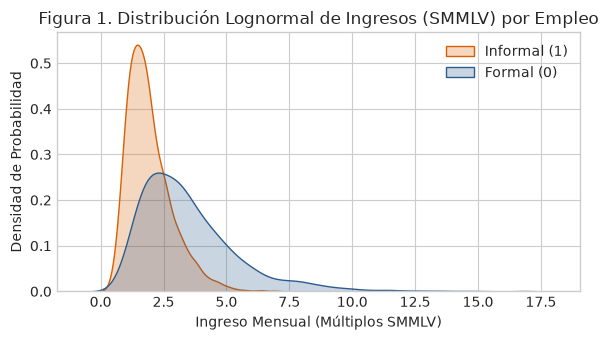

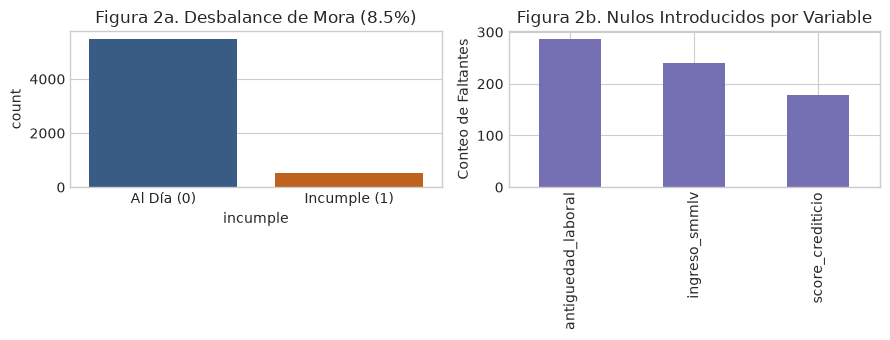

In [7]:
plt.style.use("seaborn-v0_8-whitegrid")
AZUL, NARANJA = "#2b5c8f", "#d95f02"

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.kdeplot(data=df, x="ingreso_smmlv", hue="es_informal", fill=True, common_norm=False,
            palette={1: NARANJA, 0: AZUL}, ax=ax)
ax.legend(["Informal (1)", "Formal (0)"])
ax.set(title="Figura 1. Distribución Lognormal de Ingresos (SMMLV) por Empleo",
       xlabel="Ingreso Mensual (Múltiplos SMMLV)", ylabel="Densidad de Probabilidad")
plt.tight_layout(); plt.savefig(FIGS / "fig1_distribucion_ingresos.png", dpi=300); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
sns.countplot(data=df, x="incumple", hue="incumple", palette=[AZUL, NARANJA], legend=False, ax=ax[0])
ax[0].set_xticks([0, 1], ["Al Día (0)", "Incumple (1)"])
ax[0].set_title(f"Figura 2a. Desbalance de Mora ({df.incumple.mean():.1%})")
n = df.isna().sum(); n[n > 0].plot(kind="bar", color="#7570b3", ax=ax[1])
ax[1].set(title="Figura 2b. Nulos Introducidos por Variable", ylabel="Conteo de Faltantes")
plt.tight_layout(); plt.savefig(FIGS / "fig2_diagnostico_nulos_desbalance.png", dpi=300); plt.show()

## 6. Relaciones entre variables
Correlaciones esperadas por construcción: informalidad ↔ menor score/ingreso/antigüedad y más moras previas.

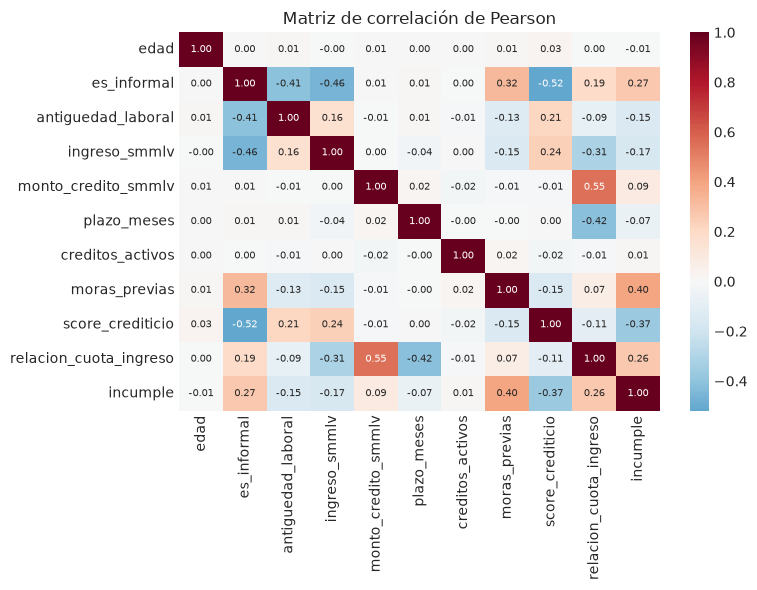

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, annot_kws={"size": 7})
ax.set_title("Matriz de correlación de Pearson")
plt.tight_layout(); plt.savefig(FIGS / "correlaciones.png", dpi=200); plt.show()